# 1 TeV 固定靶 pp 非弹性碰撞：通道和末态统计

默认 10000 次独立事件，入射动能 1000 GeV，静止质子靶，PYTHIA 8.318，种子 12345。
在 `external/` 中运行 `make pp_channel_statistics`，再运行 `./pp_channel_statistics 10000 > pp_channel_statistics.log 2>&1`。

**通道比例条件于已发生非弹性碰撞**，不包括弹性散射。过程分类由 `info.code()` 给出，不应把部分子子过程或介子衰变当成独立的 pp 通道。末态取 `isFinal()`，包括未继续衰变的带电 pion、kaon 和中子；这是当前设置的末态，不是无限时间后的产物。

In [1]:
import csv
from collections import Counter
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

folder = Path('.')
if not (folder / 'pp_channel_events.csv').exists():
    folder = Path('external')
with open(folder / 'pp_channel_events.csv') as f:
    events = list(csv.DictReader(f))
with open(folder / 'pp_channel_particles.csv') as f:
    particles = list(csv.DictReader(f))
N_events = len(events)
assert [int(e['event_id']) for e in events] == list(range(N_events))
print('Independent events:', N_events)


Independent events: 10000


## PYTHIA 过程比例

按非衍射、两种单衍射和双衍射分类。每个事件只归入一个过程，频率之和为 1。误差为各类计数的二项分布标准误，不包含生成器模型误差。

101: non-diffractive: 7086, 70.860 +/- 0.454%
103: A B -> X B single diffractive: 1106, 11.060 +/- 0.314%
104: A B -> A X single diffractive: 1129, 11.290 +/- 0.316%
105: A B -> X X double diffractive: 679, 6.790 +/- 0.252%


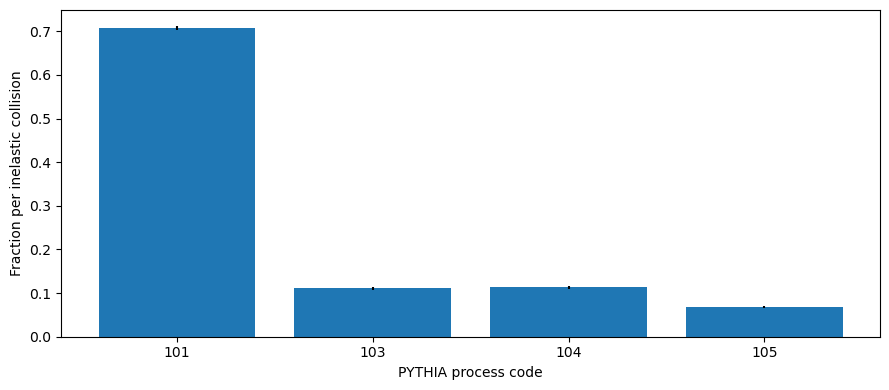

In [2]:
channel_counts = Counter(int(e['process_code']) for e in events)
channel_names = {int(e['process_code']): e['process_name'] for e in events}
codes = sorted(channel_counts)
fractions = np.array([channel_counts[c] / N_events for c in codes])
errors = np.sqrt(fractions * (1 - fractions) / N_events)
with open(folder / 'pp_channel_fractions.csv', 'w') as f:
    writer = csv.writer(f)
    writer.writerow(['process_code', 'process_name', 'count', 'fraction', 'standard_error'])
    for c, p, err in zip(codes, fractions, errors):
        writer.writerow([c, channel_names[c], channel_counts[c], p, err])
        print(f'{c}: {channel_names[c]}: {channel_counts[c]}, {100*p:.3f} +/- {100*err:.3f}%')
assert np.isclose(np.sum(fractions), 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([str(c) for c in codes], fractions, yerr=errors)
ax.set_xlabel('PYTHIA process code')
ax.set_ylabel('Fraction per inelastic collision')
fig.tight_layout()
plt.show()

## 末态粒子分布

分别统计每种粒子的平均多重数、至少出现一次的事件比例，以及每次碰撞分配给该粒子的平均总能量。不同粒子可以同时出现，出现概率之和不必为 1。反粒子单独计数。

Maximum final-energy residual [GeV]: 5.087120712232718e-06
     22 gamma          <N>=13.1878, P(>=1)=0.9389, <sum E>=191.121 GeV
    211 pi+            <N>=5.8178, P(>=1)=0.9676, <sum E>=179.229 GeV
   -211 pi-            <N>=5.1883, P(>=1)=0.9200, <sum E>=139.595 GeV
   2212 p+             <N>=1.5041, P(>=1)=0.9007, <sum E>=280.242 GeV
   2112 n0             <N>=0.9858, P(>=1)=0.6830, <sum E>=129.027 GeV
    321 K+             <N>=0.5712, P(>=1)=0.4170, <sum E>=24.481 GeV
    130 K_L0           <N>=0.4733, P(>=1)=0.3292, <sum E>=17.637 GeV
   -321 K-             <N>=0.4617, P(>=1)=0.3498, <sum E>=16.916 GeV
  -2112 nbar0          <N>=0.2471, P(>=1)=0.2166, <sum E>=11.561 GeV
  -2212 pbar-          <N>=0.2428, P(>=1)=0.2147, <sum E>=10.665 GeV
     11 e-             <N>=0.0874, P(>=1)=0.0820, <sum E>=0.702 GeV
    -11 e+             <N>=0.0871, P(>=1)=0.0818, <sum E>=0.685 GeV
    -12 nu_ebar        <N>=0.0006, P(>=1)=0.0006, <sum E>=0.006 GeV
     13 mu-            <N>=0.0006, P(>=1)

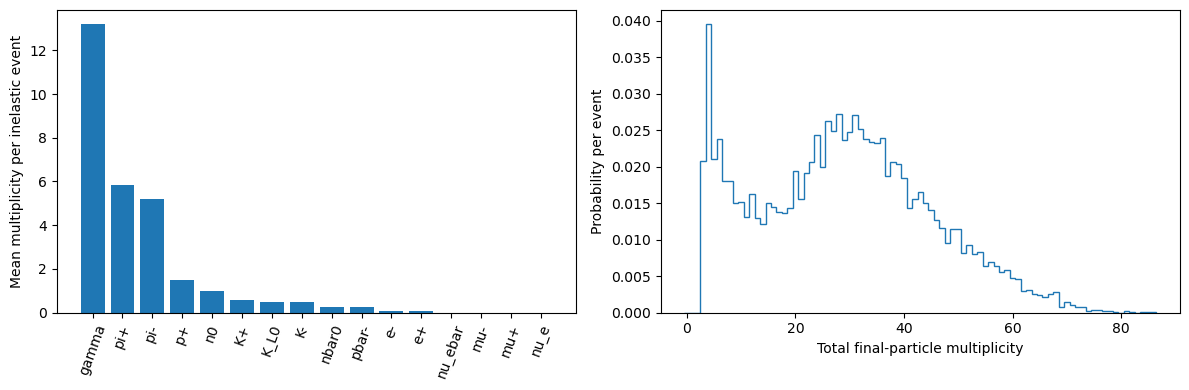

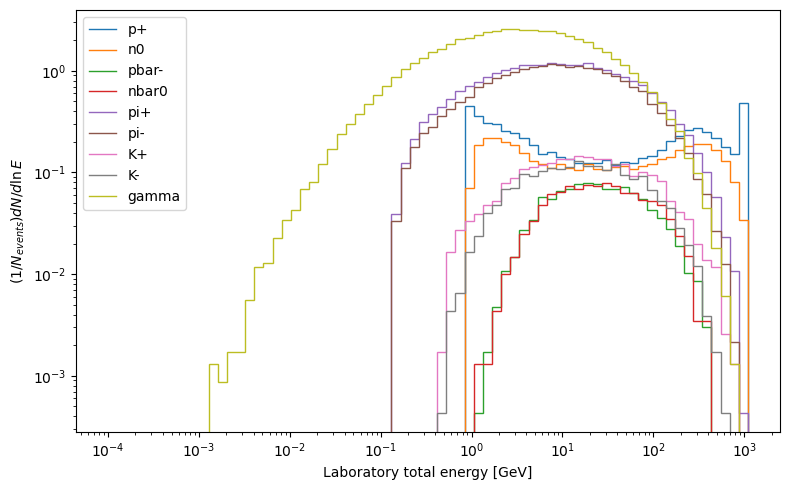

In [3]:
multiplicities = [Counter() for i in range(N_events)]
energies = {}
names = {}
energy_sum = np.zeros(N_events)
for particle in particles:
    i = int(particle['event_id'])
    pid = int(particle['pid'])
    E = float(particle['E_GeV'])
    multiplicities[i][pid] += 1
    names[pid] = particle['name']
    if pid not in energies:
        energies[pid] = []
    energies[pid].append(E)
    energy_sum[i] += E
assert all(sum(multiplicities[i].values()) == int(events[i]['N_final']) for i in range(N_events))
print('Maximum final-energy residual [GeV]:', np.max(np.abs(energy_sum - (1000 + 2*0.9382720813))))
pids = sorted(energies, key=lambda p: len(energies[p]), reverse=True)
with open(folder / 'pp_final_species.csv', 'w') as f:
    writer = csv.writer(f)
    writer.writerow(['pid', 'name', 'count', 'mean_multiplicity', 'occurrence_probability', 'mean_total_energy_per_event_GeV'])
    for pid in pids:
        mean_N = len(energies[pid]) / N_events
        prob = sum(m[pid] > 0 for m in multiplicities) / N_events
        mean_E = np.sum(energies[pid]) / N_events
        writer.writerow([pid, names[pid], len(energies[pid]), mean_N, prob, mean_E])
        print(f'{pid:7d} {names[pid]:14s} <N>={mean_N:.4f}, P(>=1)={prob:.4f}, <sum E>={mean_E:.3f} GeV')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
shown = pids[:16]
axes[0].bar([names[p] for p in shown], [len(energies[p])/N_events for p in shown])
axes[0].tick_params(axis='x', rotation=70)
axes[0].set_ylabel('Mean multiplicity per inelastic event')
N_final = np.array([int(e['N_final']) for e in events])
counts, edges = np.histogram(N_final, bins=np.arange(N_final.max()+2)-0.5)
axes[1].stairs(counts / N_events, edges)
axes[1].set_xlabel('Total final-particle multiplicity')
axes[1].set_ylabel('Probability per event')
fig.tight_layout()
fig.savefig(folder / 'pp_final_particle_distribution.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
bins = np.logspace(-4, np.log10(1100), 71)
# Inclusive yield: counts/(number of events * logarithmic bin width).
# It integrates over d ln E to the mean multiplicity within the plotted range.
for pid in [2212, 2112, -2212, -2112, 211, -211, 321, -321, 22]:
    if pid not in energies:
        continue
    counts, edges = np.histogram(energies[pid], bins=bins)
    spectrum = counts / (N_events * np.log(edges[1:] / edges[:-1]))
    ax.stairs(spectrum, edges, label=names[pid])
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Laboratory total energy [GeV]')
ax.set_ylabel(r'$(1/N_{events})dN/d\ln E$')
ax.legend()
fig.tight_layout()
fig.savefig(folder / 'pp_final_particle_spectra.png', dpi=180)
plt.show()

## 按末态粒子组合分类

下面将每种 PDG 粒子的数量作为组合签名。忽略动量、母粒子历史后，相同签名的事件合并。它们是当前衰变设置下的末态类别，不是独立矩阵元通道。高多重数事件的组合很多，因此只显示最常见的 15 类，并导出完整表。

In [4]:
combinations = Counter(tuple(sorted(m.items())) for m in multiplicities)
print('Number of distinct final-state compositions:', len(combinations))
with open(folder / 'pp_final_compositions.csv', 'w') as f:
    writer = csv.writer(f)
    writer.writerow(['composition', 'count', 'fraction'])
    for rank, (signature, count) in enumerate(combinations.most_common()):
        label = ' + '.join(f'{number} {names[pid]}' for pid, number in signature)
        writer.writerow([label, count, count/N_events])
        if rank < 15:
            print(f'{count:5d} ({100*count/N_events:.3f}%): {label}')
assert sum(combinations.values()) == N_events

Number of distinct final-state compositions: 6598
  208 (2.080%): 1 pi+ + 1 n0 + 1 p+
  206 (2.060%): 1 pi- + 1 pi+ + 2 p+
  149 (1.490%): 2 gamma + 2 p+
  134 (1.340%): 2 gamma + 1 pi+ + 1 n0 + 1 p+
  120 (1.200%): 1 pi- + 2 gamma + 1 pi+ + 2 p+
   73 (0.730%): 1 pi- + 2 gamma + 2 pi+ + 1 n0 + 1 p+
   63 (0.630%): 1 pi- + 4 gamma + 2 pi+ + 1 n0 + 1 p+
   55 (0.550%): 1 pi- + 4 gamma + 1 pi+ + 2 p+
   50 (0.500%): 4 gamma + 2 p+
   45 (0.450%): 2 pi- + 2 gamma + 2 pi+ + 2 p+
   43 (0.430%): 2 pi- + 4 gamma + 2 pi+ + 2 p+
   42 (0.420%): 1 pi- + 2 pi+ + 1 n0 + 1 p+
   41 (0.410%): 4 gamma + 1 pi+ + 1 n0 + 1 p+
   37 (0.370%): 2 pi- + 6 gamma + 2 pi+ + 2 p+
   26 (0.260%): 1 pi- + 6 gamma + 2 pi+ + 1 n0 + 1 p+


## 多事件反应通道示意图

左侧连线宽度表示各过程占全部非弹性事件的比例。右侧各框是**条件于该过程**的平均末态粒子数量 $\langle N\rangle$，不是互斥通道概率，也不是分支比；同一个事件可以同时产生这些粒子。反核子与普通核子分开统计。

末态取当前 PYTHIA 衰变设置下的最终粒子。$\pi^0$ 已衰变，因此右侧显示光子而非产生时的 $\pi^0$。图中没有将所有光子归因于 $\pi^0$。

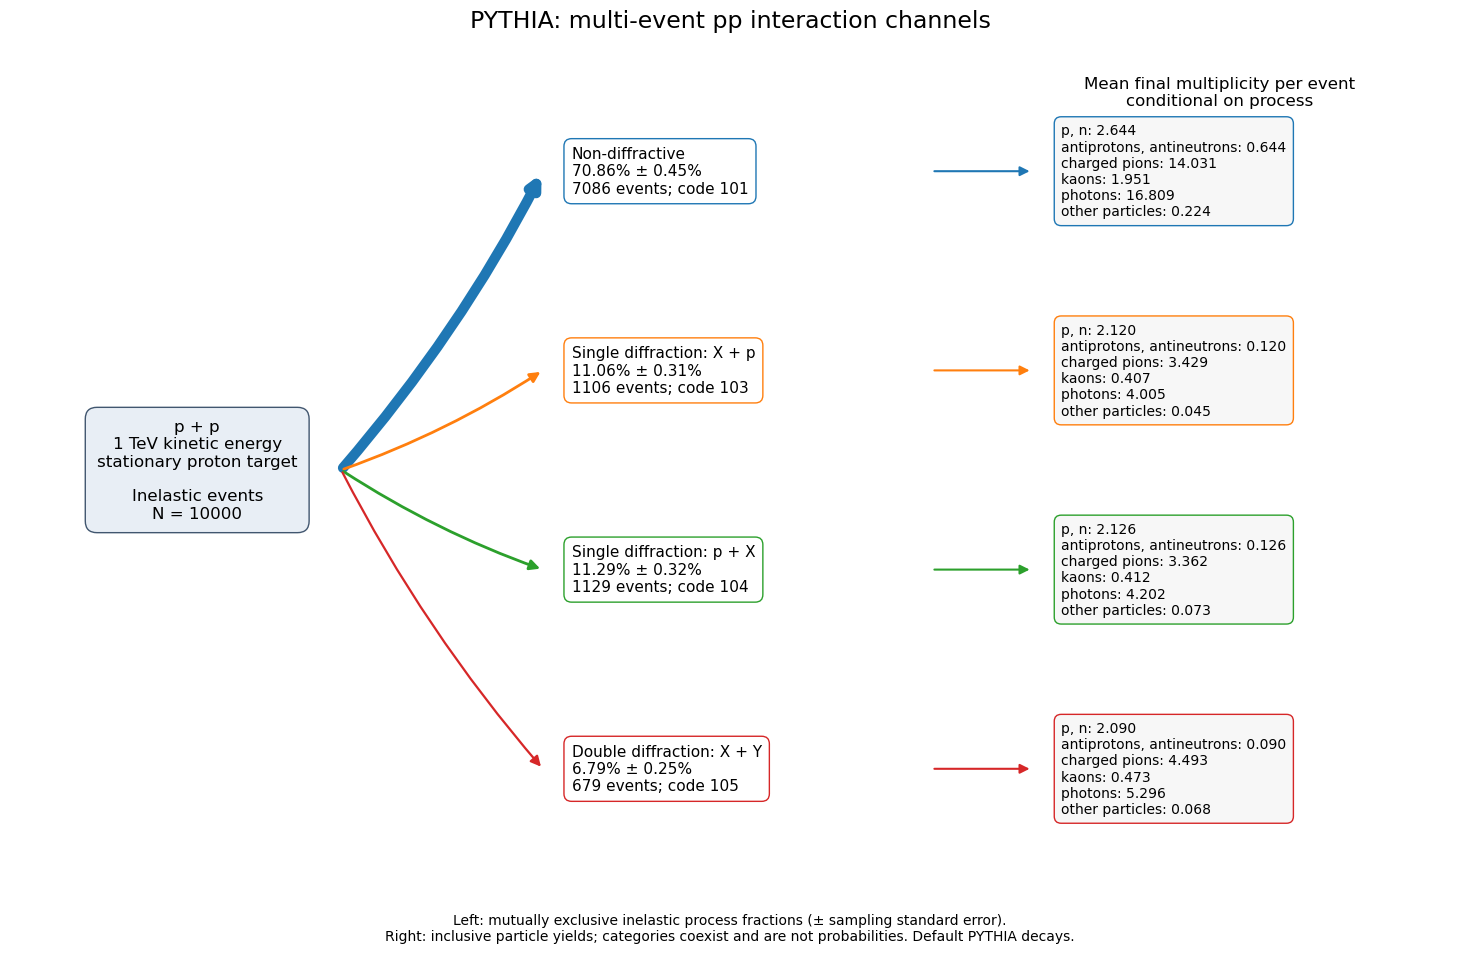

In [5]:
from matplotlib.patches import FancyArrowPatch

# Map each event to its process; count each final species within that process.
process_by_event = {int(e['event_id']): int(e['process_code']) for e in events}
groups = [
    ('p, n', [2212, 2112]),
    ('antiprotons, antineutrons', [-2212, -2112]),
    ('charged pions', [211, -211]),
    ('kaons', [321, -321, 130, 310, 311, -311]),
    ('photons', [22]),
]
yields = {code: np.zeros(len(groups) + 1) for code in codes}
for particle in particles:
    code = process_by_event[int(particle['event_id'])]
    pid = int(particle['pid'])
    group_index = len(groups)  # Other final particles, including leptons.
    for j, (label, species) in enumerate(groups):
        if pid in species:
            group_index = j
            break
    yields[code][group_index] += 1

short_names = {101: 'Non-diffractive', 103: 'Single diffraction: X + p',
               104: 'Single diffraction: p + X', 105: 'Double diffraction: X + Y'}
fig, ax = plt.subplots(figsize=(15, 10))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')
origin = (0.13, 0.5)
ax.text(*origin, 'p + p\n1 TeV kinetic energy\nstationary proton target\n\nInelastic events\nN = ' + str(N_events),
        ha='center', va='center', fontsize=12,
        bbox=dict(boxstyle='round,pad=0.7', facecolor='#e8eef5', edgecolor='#41566f'))
y_positions = np.linspace(0.86, 0.14, len(codes))
for j, (code, y) in enumerate(zip(codes, y_positions)):
    fraction = channel_counts[code] / N_events
    error = np.sqrt(fraction * (1 - fraction) / N_events)
    color = plt.get_cmap('tab10')(j)
    ax.add_patch(FancyArrowPatch((0.23, 0.5), (0.37, y), arrowstyle='-|>',
                                mutation_scale=15, linewidth=1 + 9*fraction,
                                color=color, connectionstyle='arc3,rad=0.06'))
    ax.text(0.39, y, f'{short_names.get(code, channel_names[code])}\n'
            f'{100*fraction:.2f}% ± {100*error:.2f}%\n'
            f'{channel_counts[code]} events; code {code}',
            ha='left', va='center', fontsize=11,
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor=color))
    ax.add_patch(FancyArrowPatch((0.64, y), (0.71, y), arrowstyle='-|>',
                                mutation_scale=14, linewidth=1.5, color=color))
    mean_yields = yields[code] / channel_counts[code]
    labels = [label for label, species in groups] + ['other particles']
    summary = '\n'.join(f'{label}: {value:.3f}' for label, value in zip(labels, mean_yields))
    ax.text(0.73, y, summary, fontsize=10, ha='left', va='center',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#f7f7f7', edgecolor=color))
    # Sum of grouped yields must equal the actual final multiplicity.
    expected = sum(int(e['N_final']) for e in events if int(e['process_code']) == code)
    assert int(np.sum(yields[code])) == expected
ax.text(0.84, 0.975, 'Mean final multiplicity per event\nconditional on process',
        ha='center', va='top', fontsize=12)
ax.set_title('PYTHIA: multi-event pp interaction channels', fontsize=17, pad=20)
fig.text(0.5, 0.025,
         'Left: mutually exclusive inelastic process fractions (± sampling standard error).\n'
         'Right: inclusive particle yields; categories coexist and are not probabilities. Default PYTHIA decays.',
         ha='center', fontsize=10)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.08, top=0.91)
fig.savefig(folder / 'pp_multi_event_channels.png', dpi=180)
fig.savefig(folder / 'pp_multi_event_channels.svg')
plt.show()